In [245]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
from IPython.display import Audio
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score
from imblearn.over_sampling import SMOTE
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten, BatchNormalization, Dropout
from tensorflow.keras.regularizers import l2
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import catboost as cb


In [ ]:
# Load dataset (Ensure the CSV file contains proper feature extraction)
music_data = pd.read_csv(r"C:\Users\Lenovo\Downloads\music_\Data\features_3_sec.csv")
print(music_data.head())

# Check class distribution
print(music_data['label'].value_counts())


          filename  length  chroma_stft_mean  chroma_stft_var  rms_mean  \
0  blues.00000.wav  661794          0.350088         0.088757  0.130228   
1  blues.00001.wav  661794          0.340914         0.094980  0.095948   
2  blues.00002.wav  661794          0.363637         0.085275  0.175570   
3  blues.00003.wav  661794          0.404785         0.093999  0.141093   
4  blues.00004.wav  661794          0.308526         0.087841  0.091529   

    rms_var  spectral_centroid_mean  spectral_centroid_var  \
0  0.002827             1784.165850          129774.064525   
1  0.002373             1530.176679          375850.073649   
2  0.002746             1552.811865          156467.643368   
3  0.006346             1070.106615          184355.942417   
4  0.002303             1835.004266          343399.939274   

   spectral_bandwidth_mean  spectral_bandwidth_var  ...  mfcc16_var  \
0              2002.449060            85882.761315  ...   52.420910   
1              2039.036516        

In [247]:
# Convert labels to numerical values
label_encoder = LabelEncoder()
music_data['label'] = label_encoder.fit_transform(music_data['label'])


In [248]:
# Drop filename if it exists
X = music_data.drop(['label', 'filename'], axis=1, errors='ignore')
y = music_data['label']


In [249]:
# Standardization (Better than MinMaxScaler for many cases)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert back to DataFrame
X = pd.DataFrame(X_scaled, columns=X.columns)


In [250]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [251]:
smote = SMOTE(random_state=42)
X_train, y_train = smote.fit_resample(X_train, y_train)


In [252]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import catboost as cb

rf = RandomForestClassifier(n_estimators=1000, max_depth=10, random_state=42)
gb = GradientBoostingClassifier(n_estimators=1000, learning_rate=0.05)
cbc = cb.CatBoostClassifier(verbose=0, eval_metric='Accuracy', loss_function='MultiClass')

models = [rf, gb, cbc]

for model in models:
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    acc = accuracy_score(y_test, preds)
    print(f"{model.__class__.__name__}: {acc:.4f}")


RandomForestClassifier: 0.7850
GradientBoostingClassifier: 0.7950
CatBoostClassifier: 0.7900


In [253]:
# Compute class weights for fairness
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = {i: class_weights[i] for i in range(len(class_weights))}


In [254]:
# Define Deep Learning Model
model = Sequential([
    Flatten(input_shape=(X_train.shape[1],)),
    Dense(512, activation='relu'),
    BatchNormalization(),
    Dropout(0.4),
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),
    Dense(10, activation='softmax')
])

# Compile the model
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Train the model
history = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=100, batch_size=32)




Epoch 1/100
Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: 'arguments' object has no attribute 'posonlyargs'
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert
Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: 'arguments' object has no attribute 'posonlyargs'
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert
24/28 [========================>.....] - ETA: 0s - loss: 2.9582 - accuracy: 0.1276WARNING:tensorflow:AutoGraph could not transform <function Model.make_test_function.<locals>.test_function at 0x000002666A6F04C8> and will run it as-is.
Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`)

In [255]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=1)
print(f"Test Accuracy: {test_acc:.4f}")


7/7 [==============================] - 0s 3ms/step - loss: 0.8035 - accuracy: 0.7650
Test Accuracy: 0.7650


In [ ]:
def extract_features(audio_path):
    y, sr = librosa.load(audio_path, duration=30)  # Ensure consistent duration

    features = {
        'length': len(y),
        'chroma_stft_mean': np.mean(librosa.feature.chroma_stft(y=y, sr=sr)),
        'chroma_stft_var': np.var(librosa.feature.chroma_stft(y=y, sr=sr)),
        'rms_mean': np.mean(librosa.feature.rms(y=y)),
        'rms_var': np.var(librosa.feature.rms(y=y)),
        'spectral_centroid_mean': np.mean(librosa.feature.spectral_centroid(y=y, sr=sr)),
        'spectral_centroid_var': np.var(librosa.feature.spectral_centroid(y=y, sr=sr)),
        'spectral_bandwidth_mean': np.mean(librosa.feature.spectral_bandwidth(y=y, sr=sr)),
        'spectral_bandwidth_var': np.var(librosa.feature.spectral_bandwidth(y=y, sr=sr)),
        'rolloff_mean': np.mean(librosa.feature.spectral_rolloff(y=y, sr=sr)),
        'rolloff_var': np.var(librosa.feature.spectral_rolloff(y=y, sr=sr)),
        'zero_crossing_rate_mean': np.mean(librosa.feature.zero_crossing_rate(y)),
        'zero_crossing_rate_var': np.var(librosa.feature.zero_crossing_rate(y)),
        'harmony_mean': np.mean(librosa.effects.harmonic(y)),
        'harmony_var': np.var(librosa.effects.harmonic(y)),
        'perceptr_mean': np.mean(librosa.effects.percussive(y)),
        'perceptr_var': np.var(librosa.effects.percussive(y)),
        'tempo': librosa.feature.rhythm.tempo(y=y, sr=sr)[0]
    }

    # Extract MFCCs
    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
    for i in range(1, 21):
        features[f'mfcc{i}_mean'] = np.mean(mfccs[i-1])
        features[f'mfcc{i}_var'] = np.var(mfccs[i-1])

    # Convert to DataFrame
    features_df = pd.DataFrame([features])

    # **Ensure All 58 Features Are Present**
    expected_features = [
        'length', 'chroma_stft_mean', 'chroma_stft_var', 'rms_mean', 'rms_var',
        'spectral_centroid_mean', 'spectral_centroid_var',
        'spectral_bandwidth_mean', 'spectral_bandwidth_var', 'rolloff_mean',
        'rolloff_var', 'zero_crossing_rate_mean', 'zero_crossing_rate_var',
        'harmony_mean', 'harmony_var', 'perceptr_mean', 'perceptr_var', 'tempo'
    ] + [f'mfcc{i}_mean' for i in range(1, 21)] + [f'mfcc{i}_var' for i in range(1, 21)]

    # Fill missing features with 0
    for feature in expected_features:
        if feature not in features_df.columns:
            features_df[feature] = 0

    # Ensure the correct feature order
    features_df = features_df[X_train.columns]

    return features_df


# Predict new audio
audio_path = "static/uploads/hiphop-66671.mp3"  # Update with actual path
features_df = extract_features(audio_path)

# Scale features
features_scaled = scaler.transform(features_df)

# Predict using trained model
prediction = model.predict(features_scaled)
predicted_genre = label_encoder.inverse_transform([np.argmax(prediction)])
print(f"Predicted Genre: {predicted_genre[0]}")


Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: 'arguments' object has no attribute 'posonlyargs'
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert
Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: 'arguments' object has no attribute 'posonlyargs'
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert
1/1 [==============================] - 0s 138ms/step
Predicted Genre: metal


In [257]:
from collections import Counter

# Convert predictions to genre names
y_pred_classes = np.argmax(model.predict(X_test), axis=1)
y_pred_genres = [label_encoder.inverse_transform([idx])[0] for idx in y_pred_classes]

# Count occurrences
genre_counts = Counter(y_pred_genres)

# Print results
print("Predicted Genre Distribution:")
for genre, count in genre_counts.items():
    print(f"{genre}: {count}")



7/7 [==============================] - 0s 3ms/step
Predicted Genre Distribution:
jazz: 21
pop: 10
metal: 28
hiphop: 16
reggae: 16
classical: 14
disco: 24
blues: 21
rock: 22
country: 28


In [268]:
import joblib

# Save the scaler
joblib.dump(scaler, "scaler.pkl")

# Save the label encoder
joblib.dump(label_encoder, "label_encoder.pkl")

# Save feature order (from training set)
joblib.dump(X_train.columns.tolist(), "feature_order.pkl")

# Save your trained deep learning model
model.save("model.h5")


In [258]:
print("Original Training Data Distribution:")
print(pd.Series(y_train).value_counts())  


Original Training Data Distribution:
0    87
5    87
6    87
8    87
1    87
9    87
4    87
3    87
2    87
7    87
Name: label, dtype: int64


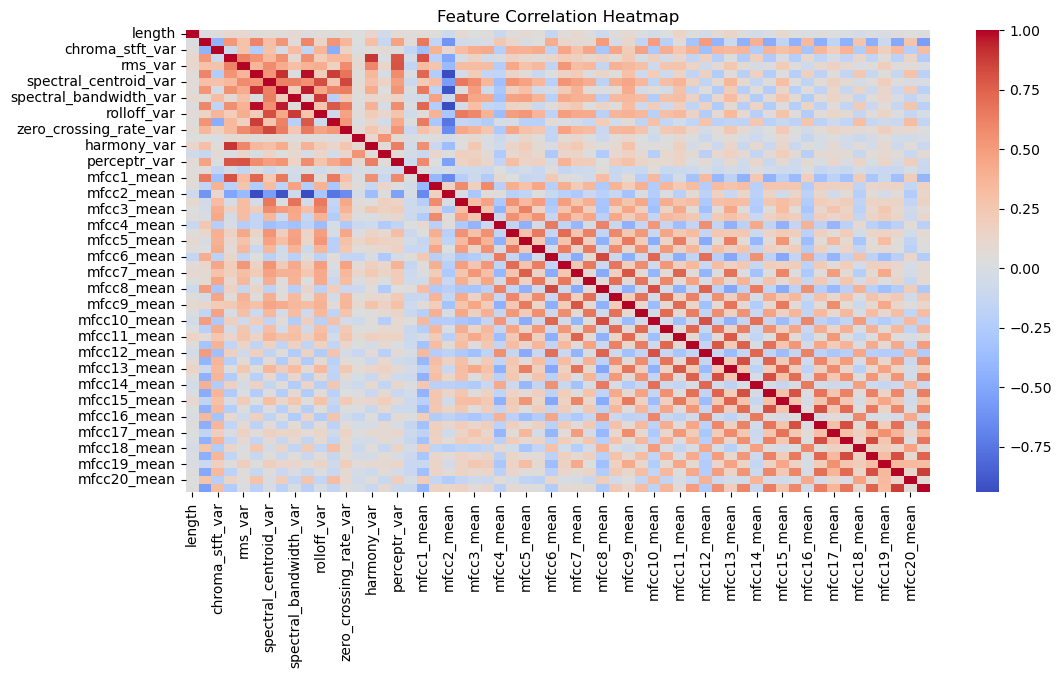

In [259]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
sns.heatmap(X_train.corr(), cmap="coolwarm", annot=False)
plt.title("Feature Correlation Heatmap")
plt.show()


In [260]:
# "static/uploads/pop-beat-62044.mp3"

In [261]:
# djembe-loop-273068.mp3 #pop
# 13-piano-l-104353.mp3 #pop
# blues-yeet-28437.mp3 #pop
# guitar-riff-30011.mp3 #blues
# flute_78_d-104176.mp3 #pop
# hiphop-66671.mp3 #pop
# jazz-effect-269183.mp3 #pop
# pop-beat-62044.mp3 #pop
# rock-music-6211.mp3 #metal
# reggae-loop-75237.mp3 #pop
# yosh-blues-guitar-78664.mp3 #pop
# synth-sample-281828.mp3 #blues
# start-this-party-193502.mp3 #pop
# single-hum-blues-69569.mp3 #jazz
# nodens-field-song-6041.mp3 #classical
# intermezzopartial-76106.mp3 #blues
# harmonica-blues-30526.mp3 #classical
# disco-77101.mp3 #classical
# country-song005-33747.mp3 #pop


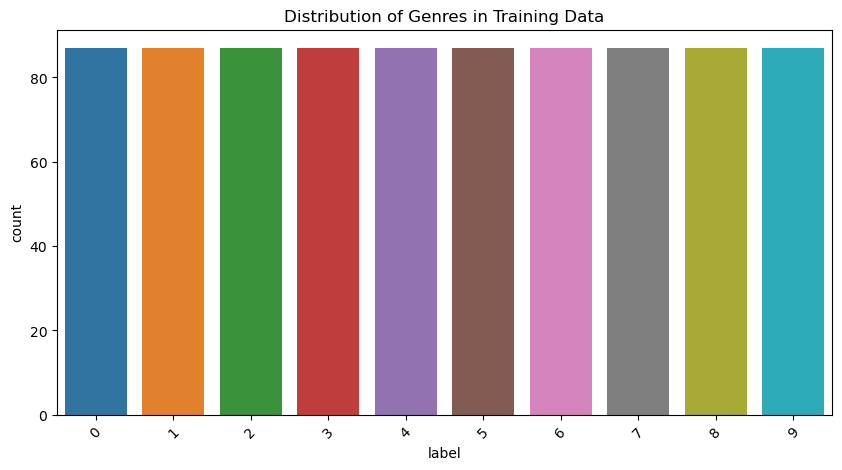

In [262]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming y_train contains the genre labels
plt.figure(figsize=(10,5))
sns.countplot(x=y_train)
plt.title("Distribution of Genres in Training Data")
plt.xticks(rotation=45)
plt.show()


In [263]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
encoder.fit(y_train)  # Fit on original genre labels
genre_mapping = dict(enumerate(encoder.classes_))


7/7 [==============================] - 0s 2ms/step


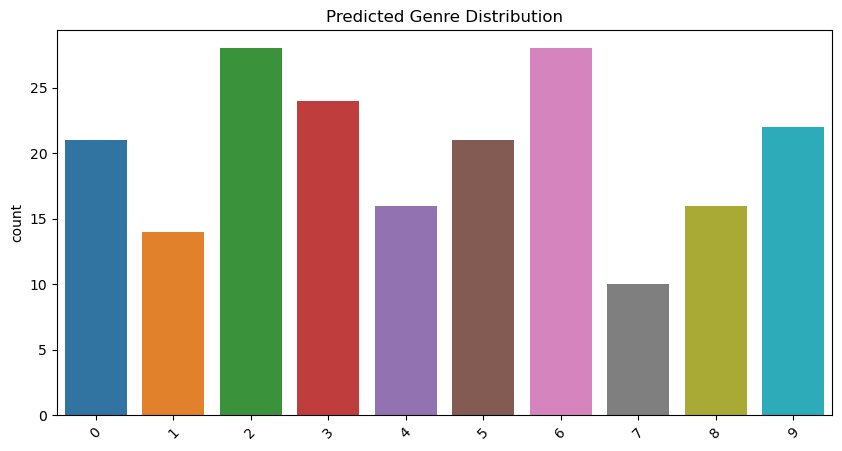

In [264]:
import numpy as np

# Predict on the test set
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)  # Convert probabilities to class index

# Convert index to genre names
y_pred_genres = [genre_mapping[idx] for idx in y_pred_classes]

# Plot predicted genre distribution
plt.figure(figsize=(10,5))
sns.countplot(x=y_pred_genres)
plt.title("Predicted Genre Distribution")
plt.xticks(rotation=45)
plt.show()


In [265]:
# genre_mapping = {
#     0: "blues", 1: "classical", 2: "country", 3: "disco", 4: "hiphop",
#     5: "jazz", 6: "metal", 7: "pop", 8: "reggae", 9: "rock"
# }


In [266]:
# from collections import Counter

# # Convert predicted class indices to genre names
# y_pred_genres = [genre_mapping[idx] for idx in y_pred_classes]

# # Count occurrences of each genre
# genre_counts = Counter(y_pred_genres)

# # Print the distribution
# print("Predicted Genre Distribution:")
# for genre, count in genre_counts.items():
#     print(f"{genre}: {count}")


In [267]:
# from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# cm = confusion_matrix(y_test, y_pred_classes)
# disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=genre_mapping.values())
# disp.plot(cmap='Blues', xticks_rotation=45)
# plt.show()
